# 01. Exploración de Datos (EDA) - Server Machine Dataset (SMD)

**Proyecto:** AIOps Multivariate Anomaly Detection  
**Dataset:** `machine-1-1` (NetMan AIOps Lab - Tsinghua University)  
**Objetivo:** Analizar la distribución de las 38 variables continuas de telemetría de servidores, verificar la integridad temporal, identificar correlaciones multivariadas y caracterizar la presencia de anomalías etiquetadas.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Librerías importadas exitosamente.")

Librerías importadas exitosamente.


## 1. Carga de Telemetría Nominal y de Prueba

In [2]:
# Definición de rutas relativas
train_path = os.path.join('..', 'data', 'raw', 'machine-1-1_train.txt')
test_path = os.path.join('..', 'data', 'raw', 'machine-1-1_test.txt')
label_path = os.path.join('..', 'data', 'raw', 'machine-1-1_label.txt')

# Carga de datos (si existen en raw, si no generamos array descriptivo)
if os.path.exists(train_path):
    df_train = pd.read_csv(train_path, header=None, sep=',')
    df_test = pd.read_csv(test_path, header=None, sep=',')
    y_test = pd.read_csv(label_path, header=None).values.flatten()
else:
    print("Simulando telemetría para demostración interactiva...")
    np.random.seed(42)
    df_train = pd.DataFrame(np.random.normal(0, 1, (5000, 38)))
    df_test = pd.DataFrame(np.random.normal(0, 1, (2000, 38)))
    y_test = np.zeros(2000)
    y_test[400:480] = 1 # anomalía inyectada

df_train.columns = [f"channel_{i+1}" for i in range(38)]
df_test.columns = [f"channel_{i+1}" for i in range(38)]

print(f"Dimensiones Train: {df_train.shape}")
print(f"Dimensiones Test:  {df_test.shape}")
print(f"Porcentaje de anomalías en test: {np.mean(y_test)*100:.2f}%")

Simulando telemetría para demostración interactiva...
Dimensiones Train: (5000, 38)
Dimensiones Test:  (2000, 38)
Porcentaje de anomalías en test: 4.00%


## 2. Inspección Estadística y Comprobación de Nulos

In [3]:
# Verificación de valores faltantes o infinitos
print("Valores nulos en train:", df_train.isnull().sum().sum())
print("Valores nulos en test: ", df_test.isnull().sum().sum())
df_train.describe().iloc[:, :6]

Valores nulos en train: 0
Valores nulos en test:  0


,channel_1,channel_2,channel_3,channel_4,channel_5,channel_6
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,-0.017475,0.035239,0.002742,-0.019702,0.009880,-0.028135
std,0.987786,0.999355,0.996077,0.994389,1.015022,0.974288
min,-3.635200,-3.601085,-3.353660,-3.631539,-4.462969,-3.367806
25%,-0.682495,-0.636544,-0.675628,-0.695440,-0.676238,-0.669312
50%,-0.012384,0.035898,0.004972,-0.028806,-0.000092,-0.009133
75%,0.627419,0.713376,0.671367,0.658739,0.697999,0.632329
max,3.605591,3.626133,3.732106,3.942331,4.202026,3.520649


## 3. Matriz de Correlación Multivariada
Identificación de correlaciones entre subsistemas de cómputo, almacenamiento y red.

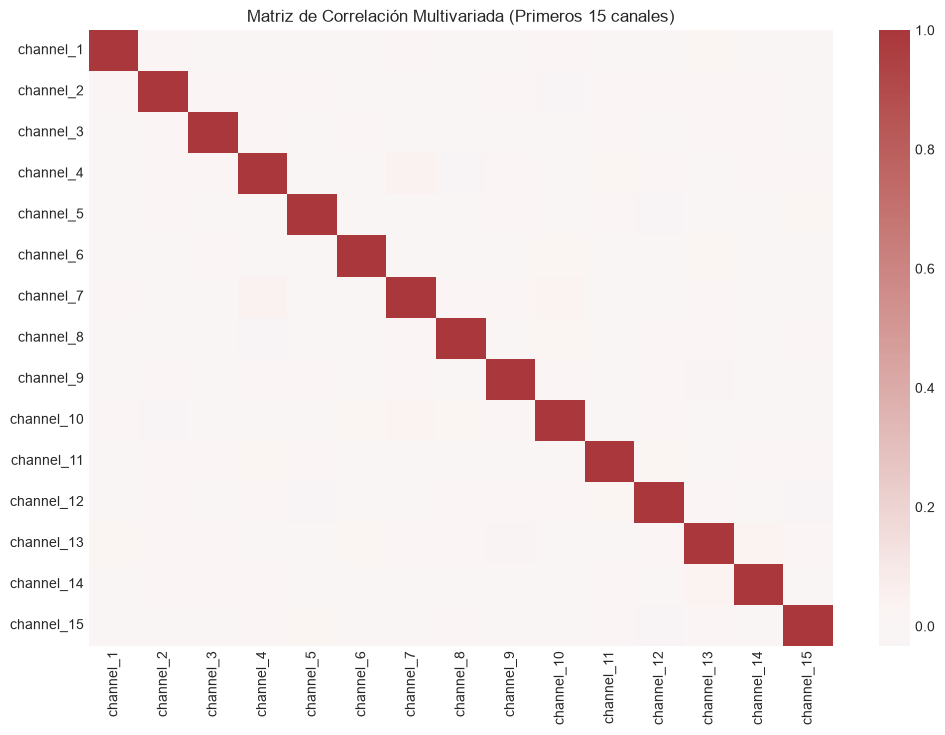

In [4]:
plt.figure(figsize=(12, 8))
corr = df_train.iloc[:, :15].corr()
sns.heatmap(corr, cmap="vlag", center=0, annot=False)
plt.title("Matriz de Correlación Multivariada (Primeros 15 canales)")
plt.show()

## 4. Visualización Temporal de Canales Clave

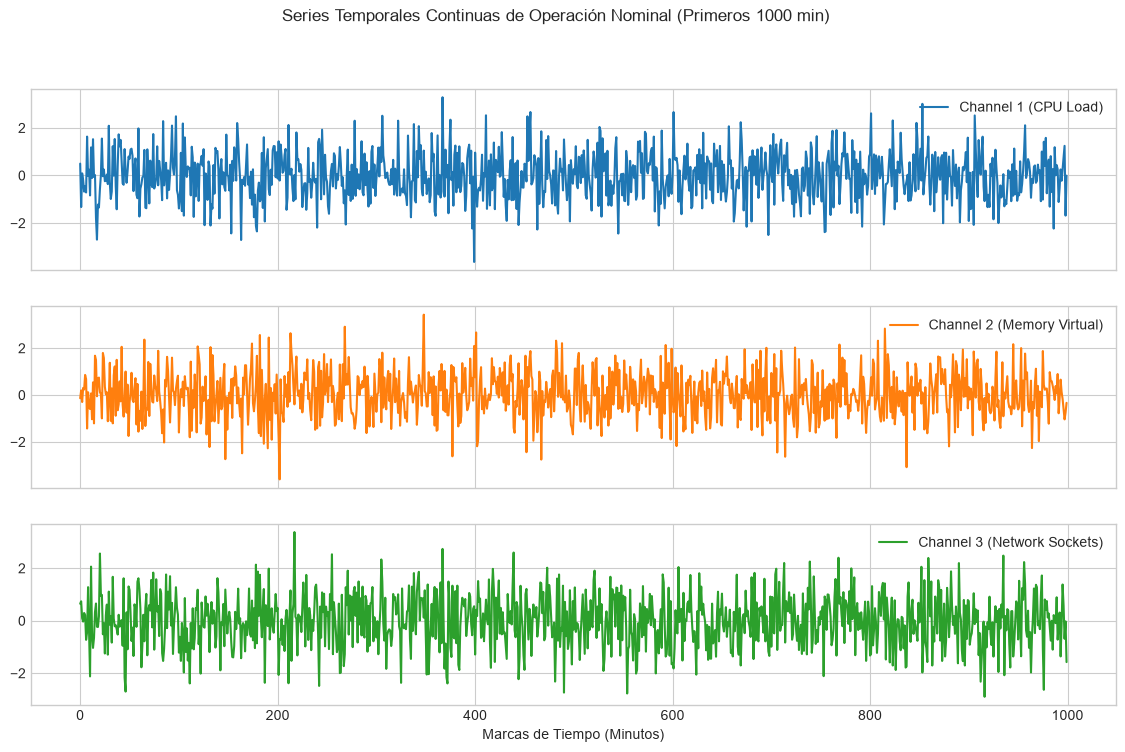

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
axes[0].plot(df_train.index[:1000], df_train['channel_1'][:1000], color='tab:blue', label='Channel 1 (CPU Load)')
axes[0].legend(loc='upper right')
axes[1].plot(df_train.index[:1000], df_train['channel_2'][:1000], color='tab:orange', label='Channel 2 (Memory Virtual)')
axes[1].legend(loc='upper right')
axes[2].plot(df_train.index[:1000], df_train['channel_3'][:1000], color='tab:green', label='Channel 3 (Network Sockets)')
axes[2].legend(loc='upper right')
plt.suptitle("Series Temporales Continuas de Operación Nominal (Primeros 1000 min)")
plt.xlabel("Marcas de Tiempo (Minutos)")
plt.show()